In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import argparse
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
sys.path.append('..')
from models.common_autoencoder_blocks import Encoder  
from models.cifar10_supconv import CIFAR10SupCon
from trainers.supcon_trainer import SupConTrainer
from trainers.classifier_trainer import ClassifierTrainer
from models.cifar10_classifier import CIFAR10Classifier
device = 'cuda' if torch.cuda.is_available() else 'cpu'

import numpy as np
import random

In [2]:
class TwoCropsTransform:
    def __init__(self, base_transform):
        self.base_transform = base_transform

    def __call__(self, x):
        im1 = self.base_transform(x)
        im2 = self.base_transform(x)
        return im1, im2


base_transform = transforms.Compose([
    transforms.RandomResizedCrop(32, scale=(0.2, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.GaussianBlur(kernel_size=3),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

train_transform = TwoCropsTransform(base_transform)
val_base_transform = transforms.Compose([transforms.ToTensor()])
val_transform = TwoCropsTransform(val_base_transform)
test_transform = TwoCropsTransform(val_base_transform)

data_path = os.path.join("..", "data")


In [3]:
full_train_dataset = datasets.CIFAR10(root=data_path, train=True, download=True)
test_dataset   = datasets.CIFAR10(root=data_path, train=False, download=True)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)


train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False, num_workers=2, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False, num_workers=2, drop_last=True)


Files already downloaded and verified
Files already downloaded and verified


[Epoch 1] TrainLoss=7.0048, ValLoss=6.8444, TestLoss=6.8453
[Epoch 2] TrainLoss=6.8886, ValLoss=6.8413, TestLoss=6.8444
[Epoch 3] TrainLoss=6.8604, ValLoss=6.8331, TestLoss=6.8357
[Epoch 4] TrainLoss=6.8377, ValLoss=6.8404, TestLoss=6.8417
[Epoch 5] TrainLoss=6.8045, ValLoss=6.8461, TestLoss=6.8482
[Epoch 6] TrainLoss=6.7756, ValLoss=6.8158, TestLoss=6.8172
[Epoch 7] TrainLoss=6.7323, ValLoss=6.7462, TestLoss=6.7450
[Epoch 8] TrainLoss=6.6925, ValLoss=6.7481, TestLoss=6.7468
[Epoch 9] TrainLoss=6.6499, ValLoss=6.7096, TestLoss=6.7077
[Epoch 10] TrainLoss=6.6232, ValLoss=6.7500, TestLoss=6.7505
[Epoch 11] TrainLoss=6.5894, ValLoss=6.6663, TestLoss=6.6704
[Epoch 12] TrainLoss=6.5646, ValLoss=6.6741, TestLoss=6.6784
[Epoch 13] TrainLoss=6.5414, ValLoss=6.6106, TestLoss=6.6182
[Epoch 14] TrainLoss=6.5158, ValLoss=6.5549, TestLoss=6.5572
[Epoch 15] TrainLoss=6.4928, ValLoss=6.5047, TestLoss=6.4976
[Epoch 16] TrainLoss=6.4656, ValLoss=6.5630, TestLoss=6.5685
[Epoch 17] TrainLoss=6.4505, ValL

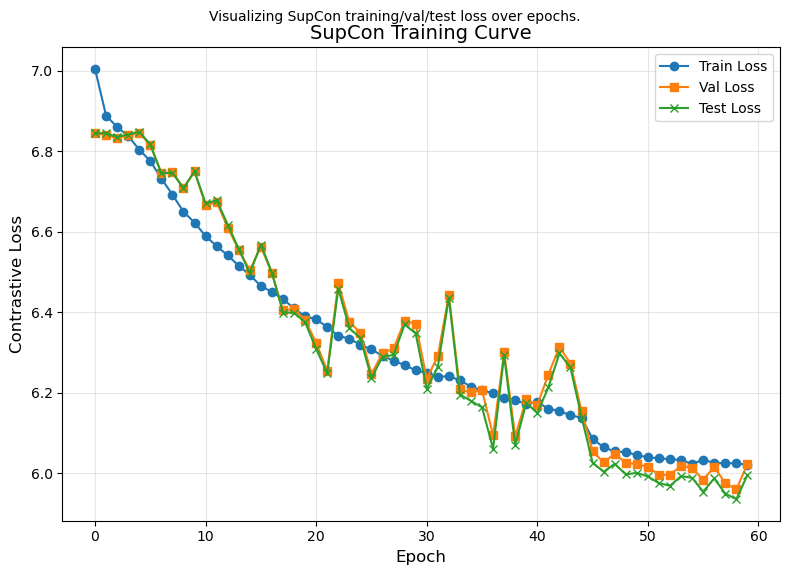

=== Final SupCon Metrics ===
Train Loss: 6.0210
Val   Loss: 6.0229
Test  Loss: 5.9960


In [4]:
supcon = CIFAR10SupCon(
    input_shape=(3, 32, 32),
    channels=[ 64, 128,256,128],  # maybe deeper for CIFAR10
    kernel_sizes=[3,3,3,3],
    strides=[1,2,2,1],
    paddings=[1, 1, 1,1],
    latent_dim=128,
    dropout_rate=0.2,
    hidden_dims=[256],
    batch_norm_conv=True
)
optimizer = torch.optim.Adam(supcon.parameters(), lr=3e-4, weight_decay=1e-4)

supcon_trainer = SupConTrainer(
    model=supcon,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader = test_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=60,
    patience=10,
    scheduler_type="plateau",
    temperature=0.07
)
supcon_trainer.train()
supcon_trainer.plot_metrics()

In [5]:
classification_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),  
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

classification_val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

classification_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

full_train_dataset_cla= datasets.CIFAR10(root=data_path, train=True, download=True)
cla_test_dataset  = datasets.CIFAR10(root=data_path, train=False, download=True)

cla_train_size = int(0.8 * len(full_train_dataset))
cla_val_size = len(full_train_dataset) - train_size
cla_train_subset, cla_val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
train_dataset_classification = TransformedSubset(cla_train_subset, classification_train_transform)
val_dataset_classification = TransformedSubset(cla_val_subset, classification_val_transform)
test_dataset_classification = TransformedSubset(cla_test_dataset, classification_test_transform)


Files already downloaded and verified
Files already downloaded and verified


Epoch [1] - TrainAcc: 0.4674, ValAcc: 0.7636, TestAcc: 0.7433 | ValLoss: 1.3635
Epoch [2] - TrainAcc: 0.7248, ValAcc: 0.7912, TestAcc: 0.7664 | ValLoss: 0.9773
Epoch [3] - TrainAcc: 0.7430, ValAcc: 0.7981, TestAcc: 0.7756 | ValLoss: 0.8027
Epoch [4] - TrainAcc: 0.7523, ValAcc: 0.8018, TestAcc: 0.7796 | ValLoss: 0.7096
Epoch [5] - TrainAcc: 0.7586, ValAcc: 0.8067, TestAcc: 0.7837 | ValLoss: 0.6664
Epoch [6] - TrainAcc: 0.7639, ValAcc: 0.8106, TestAcc: 0.7846 | ValLoss: 0.6285
Epoch [7] - TrainAcc: 0.7664, ValAcc: 0.8138, TestAcc: 0.7878 | ValLoss: 0.6024
Epoch [8] - TrainAcc: 0.7688, ValAcc: 0.8175, TestAcc: 0.7908 | ValLoss: 0.5870
Epoch [9] - TrainAcc: 0.7691, ValAcc: 0.8210, TestAcc: 0.7911 | ValLoss: 0.5740
Epoch [10] - TrainAcc: 0.7731, ValAcc: 0.8224, TestAcc: 0.7932 | ValLoss: 0.5605
Epoch [11] - TrainAcc: 0.7747, ValAcc: 0.8249, TestAcc: 0.7972 | ValLoss: 0.5508
Epoch [12] - TrainAcc: 0.7758, ValAcc: 0.8242, TestAcc: 0.7972 | ValLoss: 0.5437
Epoch [13] - TrainAcc: 0.7754, ValAcc

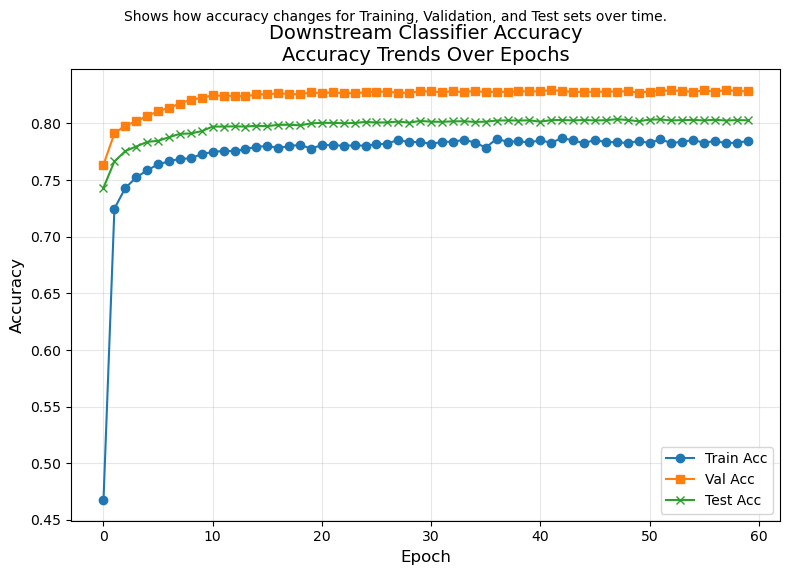

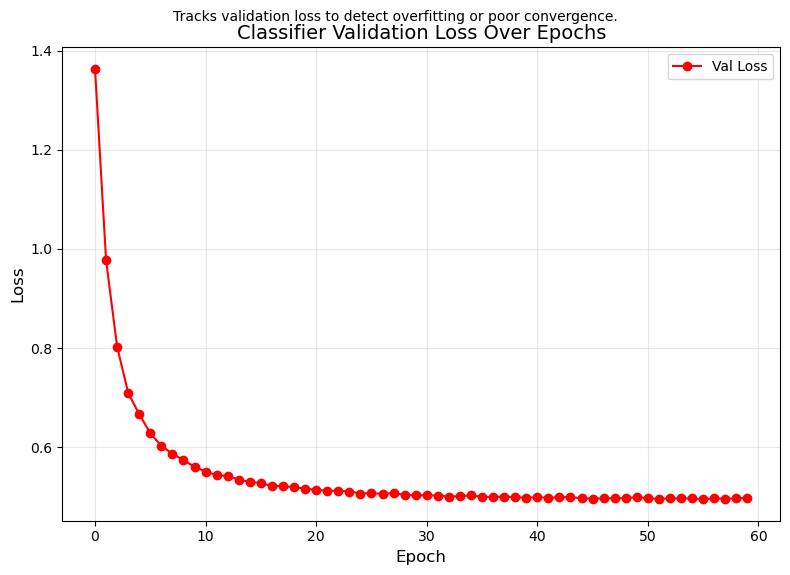

=== Final Classifier Metrics ===
Val Loss: 0.4976
Train Acc: 78.43%
Val   Acc: 82.83%
Test  Acc: 80.27%


In [7]:
train_classification_loader = DataLoader(train_dataset_classification, batch_size=1024, shuffle=True)
val_classification_loader = DataLoader(val_dataset_classification, batch_size=1024, shuffle=False)
test_classification_loader = DataLoader(test_dataset_classification, batch_size=1024, shuffle=False)
classifier = CIFAR10Classifier(latent_dim=128, num_classes=10, dropout_fc=0.2, batch_norm_fc=True)
classifier_trainer = ClassifierTrainer(
    encoder=supcon,
    classifier=classifier,
    train_loader=train_classification_loader,
    val_loader=val_classification_loader,
    test_loader = test_classification_loader,
    device=device,
    lr=1e-4,
    weight_decay=1e-4,
    scheduler_type="cosine",
    T_max = 60,
    num_epochs=60,
    patience=10,
)

# Train and plot as before
classifier_trainer.train()
classifier_trainer.plot_metrics()


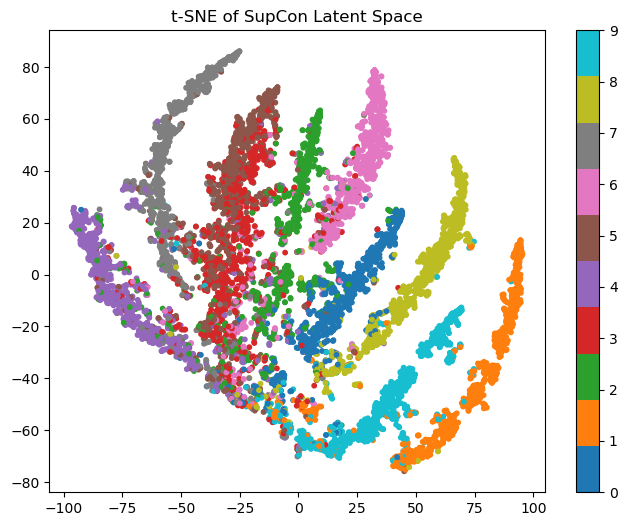

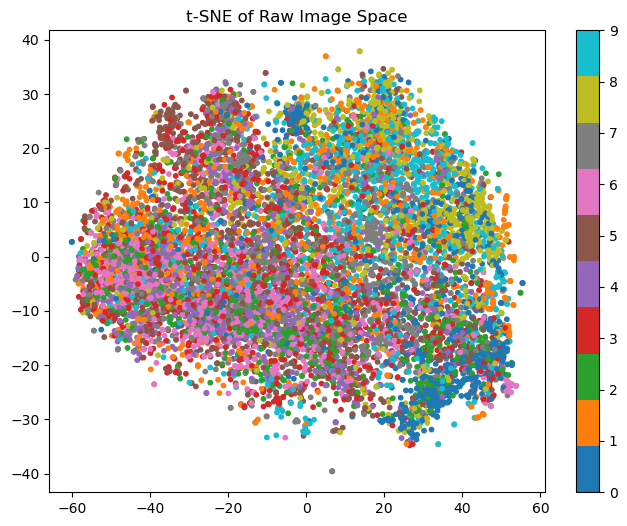

In [9]:
from utils import plot_tsne_supcon
plot_tsne_supcon(supcon, test_classification_loader, device='cuda')
